# Fashion recommender: a guided walkthrough

This notebook takes you through the whole project, from raw purchase data to a ranked list of 12 articles per customer, in the order things actually happen.
Run it **top to bottom, one cell at a time**. Every section has the same shape:

1. **What and why**: a short explanation in plain language (read this first).
2. **Code**: the real project code (`src/`), called step by step so you can see each piece working.
3. **How to read the output**: what to look for and what it means.

**The task.** For each H&M customer, using everything they bought before week *W*, recommend 12 articles they will buy **for the first time** in week *W*.

**What you will have understood at the end**
- how the data is split in time so that nothing from the future leaks into training (and a leak I found and fixed in my own setup),
- how recall@12 and NDCG@12 work, from first principles,
- four simple "candidate generators" and why a recency-weighted one wins,
- how a LightGBM ranker combines them and how much it really adds (with confidence intervals),
- why more candidates stop helping, what the two-tower model did and did not do, and what the cold-start experiment shows,
- which claims are safe to make about this project and which are not.

| Section | Topic | Rough time (default settings) |
|---|---|---|
| 0 | Setup | seconds |
| 1 | The data | about 30 seconds (reads a 3.5 GB file in chunks) |
| 2 | Time-based evaluation and the leak | about 15 seconds |
| 3 | Metrics from scratch | seconds |
| 4 | Baselines | about 15 seconds |
| 5 | Article text embeddings | about 30 seconds |
| 6 | Candidate generation | about 1 minute |
| 7 | Features | seconds |
| 8 | The ranker | under 1 minute |
| 9 | Looking at real recommendations | seconds |
| 10 | Does a bigger candidate pool help? | about 2 to 3 minutes |
| 11 | Two-tower model (read, optional run) | seconds (optional run: about 5 minutes) |
| 12 | Cold start (read, optional run) | seconds (optional run: about 8 minutes) |
| 13 | How reliable are the numbers? (seeds) | about 1 minute |
| 14 | Summary: what is safe to claim | seconds |

With the default settings the whole notebook runs in **about 6 to 8 minutes** on a 10-core Mac. It uses a **sample of customers**, so numbers are close to but noisier than the full-run numbers in the README
(with 5,000 test customers, expect differences of a few thousandths in recall@12, and 95% intervals of about +/-0.005). Setting `N_TEST = None` and `N_TRAIN = None` uses everyone and matches the README, but takes 30+ minutes and several GB of memory.
The outputs saved in this file came from the default settings. If the kernel dies in section 6, lower `N_TEST` and `N_TRAIN`.

## Before you run anything

- **Kernel:** use the same Python environment you use for the project (the one that has `lightgbm`, `scikit-learn`, `pandas`, `matplotlib`).
- **Do not import `torch` in this notebook.** On macOS, PyTorch and LightGBM each ship their own OpenMP library and crash when both are loaded in one process. This is why the two-tower and cold-start steps (sections 11 and 12) are run as *separate processes* and only read here.
- **Data:** `data/hm/transactions_train.csv` and `data/hm/articles.csv` (from the Kaggle H&M competition) must exist. The first cell checks.
- **Working directory:** the notebook finds the repository root by itself, whether you open it from `notebooks/` or from the root.

## 0. Setup

The cell below imports libraries, locates the repository and sets the **knobs** you can change:

- `N_TEST`: how many test customers to evaluate (`None` means all, about 40,000; slower but matches the README).
- `N_TRAIN`: how many validation-week customers to train the ranker on (`None` means 40,000 as in the README).
- `SEED`: the random seed for sampling customers.
- `IMAGES_ZIP`: optional path to the competition's `images.zip`; with it, section 9 shows a picture for every article (otherwise only the 725 thumbnails in `demo/images` appear, the rest are grey boxes).

In [1]:
import os, sys, time, inspect, re, subprocess, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML, Image

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 40, "display.width", 140, "display.float_format", lambda v: f"{v:,.4f}")

REPO = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(REPO))
os.chdir(REPO)
DATA = REPO / "data" / "hm"
assert (DATA / "transactions_train.csv").exists() and (DATA / "articles.csv").exists(), (
    "Put transactions_train.csv and articles.csv from the Kaggle H&M competition into data/hm/ first (see the README).")

# ---- knobs (change these) --------------------------------------------------------------------
N_TEST = 5000      # test customers to evaluate; None = all (~40k)
N_TRAIN = 15000    # validation-week customers to train the ranker on; None = 40,000 like the README
SEED = 0
K = 12             # we always recommend 12 articles
IMAGES_ZIP = os.environ.get("HM_IMAGES_ZIP")   # optional: path to the competition's images.zip, to show a picture for ANY article (section 9)

assert "torch" not in sys.modules, "torch must not be loaded in this kernel (it crashes LightGBM on macOS)"
t0 = time.time()
def tick(msg=""):
    print(f"[{time.time() - t0:6.0f}s] {msg}")
print("repository root:", REPO.name)

repository root: fashion-recsys


## 1. The data

**What and why.** H&M published about two years of real purchases. Each row is one purchase: *who* (`customer_id`), *what* (`article_id`), *when* (`t_dat`) and the `price`.
A second file, `articles.csv`, describes every article (name, product type, colour, department, a text description).

Two choices happen while loading (see `src/hm.py`):
- We keep only the **last 26 weeks**, the part of the data a recommender would realistically learn from.
- If a customer bought the same article twice, we keep only the **first** purchase. This project is about *new-to-customer discovery*: we never recommend something a customer already bought. That makes it narrower than the original Kaggle task (which allowed repeat purchases), so **our numbers are not comparable to the Kaggle leaderboard**.

Reading the 3.5 GB CSV takes a minute or two. It is read in chunks so memory stays small.

In [2]:
from src.hm import load_hm

raw = load_hm(str(DATA / "transactions_train.csv"), last_weeks=26)
raw["date"] = pd.to_datetime(raw["timestamp"], unit="ms")
tick("loaded")
print(f"{len(raw):,} purchases | {raw.user_id.nunique():,} customers | {raw.item_id.nunique():,} articles")
print("date range:", raw.date.min().date(), "to", raw.date.max().date())
display(raw.drop(columns="timestamp").head())

[    23s] loaded


7,062,867 purchases | 745,513 customers | 51,375 articles
date range: 2020-03-24 to 2020-09-22


,user_id,item_id,price,date
0,0001d44dbe7f6c4b35200abdb052c77a87596fe1bdcc37...,803757008,0.0164,2020-03-24
1,0001d44dbe7f6c4b35200abdb052c77a87596fe1bdcc37...,888334001,0.0164,2020-03-24
2,0001d44dbe7f6c4b35200abdb052c77a87596fe1bdcc37...,759814011,0.0196,2020-03-24
3,0001d44dbe7f6c4b35200abdb052c77a87596fe1bdcc37...,803757004,0.0131,2020-03-24
4,0001d44dbe7f6c4b35200abdb052c77a87596fe1bdcc37...,838787001,0.0245,2020-03-24


**How to read this.** `item_id` has no leading zeros here (we store articles as plain numbers); `articles.csv` has them padded to 10 digits. Prices are scaled by H&M, not real currency.
`user_id` is a long hashed string: H&M anonymised the customers.

Next, two pictures of the data that matter for everything that follows: purchases per week, and how unevenly purchases are spread across articles.

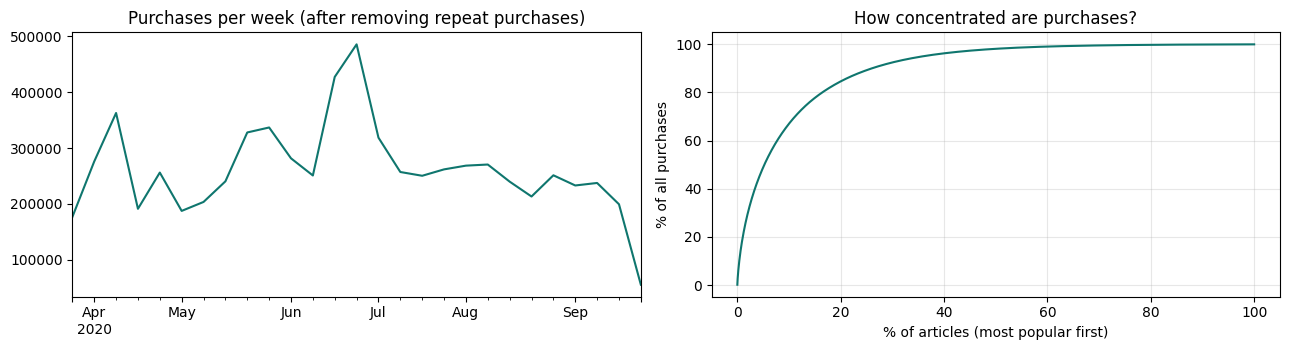

The most popular 1% of articles account for 19% of all purchases.


In [3]:
weekly = raw.set_index("date").resample("W").size()
pop = raw.item_id.value_counts()
share = pop.cumsum() / pop.sum()

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
weekly.plot(ax=ax[0], color="#0f766e"); ax[0].set_title("Purchases per week (after removing repeat purchases)"); ax[0].set_xlabel("")
ax[1].plot(np.arange(1, len(share) + 1) / len(share) * 100, share.values * 100, color="#0f766e")
ax[1].set_title("How concentrated are purchases?"); ax[1].set_xlabel("% of articles (most popular first)"); ax[1].set_ylabel("% of all purchases")
ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()
top1 = share.iloc[int(len(share) * 0.01)] * 100
print(f"The most popular 1% of articles account for {top1:.0f}% of all purchases.")

**How to read this.** The left plot shows seasonality: demand moves from week to week, which is why one test week is not enough evidence and why we later test on four different weeks.
The right plot is the *long tail*: a small share of articles gets most purchases. This is why "recommend what is popular" is a surprisingly strong baseline, and why a good recommender must not collapse onto a few popular articles.

Now the article table, which we will use for article names, categories and text.

105,542 articles


,article_id,prod_name,product_type_name,colour_group_name,department_name,detail_desc
38159,0656677021,Legolas SS,Shirt,White,Shirt,Short-sleeved shirt in a patterned viscose wea...
69760,0758050001,LS Olivia Cheeky Tanga,Swimwear bottom,Light Beige,Swimwear,LOVE STORIES x H&M. Patterned bikini bottoms w...
55574,0711043002,Georgia Shorts,Shorts,Other Pink,Bottoms Girls,Sports shorts in fast-drying functional fabric...
88565,0833548001,Ridgeback jacket,Jacket,Black,Outwear,Short coat in woven fabric with no buttons. Si...
79069,0796535023,Palmita tee,T-shirt,Dark Grey,Kids Girl Jersey Fancy,Short-sleeved top in printed cotton jersey.


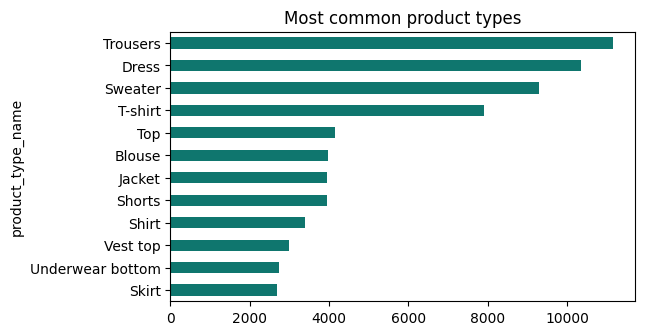

In [4]:
arts = pd.read_csv(DATA / "articles.csv", dtype={"article_id": str})
arts["item_id"] = arts["article_id"].astype(int).astype(str)      # same key as the purchase table
arts_by_id = arts.set_index("item_id")
print(f"{len(arts):,} articles")
display(arts[["article_id", "prod_name", "product_type_name", "colour_group_name", "department_name", "detail_desc"]].sample(5, random_state=1))
arts.product_type_name.value_counts().head(12).sort_values().plot.barh(color="#0f766e", figsize=(6, 3.5), title="Most common product types")
plt.show()

## 2. Evaluating honestly: time-based splits, and a leak I had to fix

**What and why.** A recommender is used to predict the *future*, so it must be tested on the future. We split by calendar time, not randomly:

| Period | What it is used for |
|---|---|
| everything before the last two weeks | **training period** (learn from it) |
| the week before the last | **validation week** (tune things, and train the ranker's labels) |
| the final week | **test week** (the only place we report results) |

For the **test** we give models the history *up to the start of the test week* and score them on what customers bought *during* it.
For the **validation** phase the history stops one week earlier. (`src/phases.py` builds both.)

**The leak.** We keep only customers and articles with at least 5 purchases ("5-core"), so that there is something to learn from. My first version applied that filter to *all 26 weeks* before splitting.
That means a purchase in the test week could make an article eligible. That is future information deciding what the model is allowed to see, and a reviewer pointed it out. The fix: compute eligibility **on the training period only** and freeze it.
The toy example below shows the difference in miniature.

In [5]:
from src.data import k_core, last_days_split_kcore

DAY = 24 * 3600 * 1000
rows = []
for u in ("u1", "u2", "u3", "u4"):                     # everybody buys articles a, c, d early
    rows += [(u, i, 1 * DAY) for i in "acd"]
rows += [("u1", "b", 2 * DAY), ("u2", "b", 3 * DAY)]                              # article b: 2 purchases in the training period
rows += [("u3", "b", 28 * DAY), ("u4", "b", 29 * DAY), ("u1", "b", 30 * DAY)]     # ...and 3 more in the FUTURE (test period)
toy = pd.DataFrame(rows, columns=["user_id", "item_id", "timestamp"])

print("Old (leaky) filter keeps article b:     ", "b" in set(k_core(toy, 3).item_id))
print("New (leak-free) filter keeps article b: ", "b" in set(last_days_split_kcore(toy, core=3).item_ids))

Old (leaky) filter keeps article b:      True
New (leak-free) filter keeps article b:  False


**How to read this.** Article `b` only reaches 3 purchases because of purchases in the *future*. The old filter keeps it (leak); the new one drops it (correct). This exact case is a unit test in `tests/test_basics.py`, so the leak cannot come back unnoticed.

Now the real split. `last_days_split_kcore` computes the 5-core on the training period, then splits by calendar. `make_phases` builds the two phases we will use throughout.

In [6]:
from src.data import last_days_split_kcore
from src.phases import make_phases

split = last_days_split_kcore(raw, core=5)
val, test = make_phases(split)
tick("split done")
print(f"eligible customers: {split.n_users:,} | eligible articles: {split.n_items:,}")
for ph in (val, test):
    print(f"{ph.name:>4}: history = {len(ph.hist):,} purchases, ends {pd.to_datetime(ph.hist.timestamp.max(), unit='ms').date()} | "
          f"labels = {len(ph.labels):,} purchases by {ph.labels.u.nunique():,} customers, "
          f"{pd.to_datetime(ph.labels.timestamp.min(), unit='ms').date()} to {pd.to_datetime(ph.labels.timestamp.max(), unit='ms').date()}")
    assert ph.hist.timestamp.max() < ph.labels.timestamp.min(), "history must end before labels begin"
print("\nchronology check passed: for both phases the history ends before the labels begin")
print(f"customers evaluated in the test week: {test.labels.u.nunique():,} = {test.labels.u.nunique() / split.n_users:.1%} of eligible customers")

[    32s] split done
eligible customers: 414,131 | eligible articles: 33,801
 val: history = 5,877,972 purchases, ends 2020-09-08 | labels = 137,516 purchases by 44,617 customers, 2020-09-09 to 2020-09-15
test: history = 6,015,488 purchases, ends 2020-09-15 | labels = 114,859 purchases by 40,188 customers, 2020-09-16 to 2020-09-22

chronology check passed: for both phases the history ends before the labels begin
customers evaluated in the test week: 40,188 = 9.7% of eligible customers


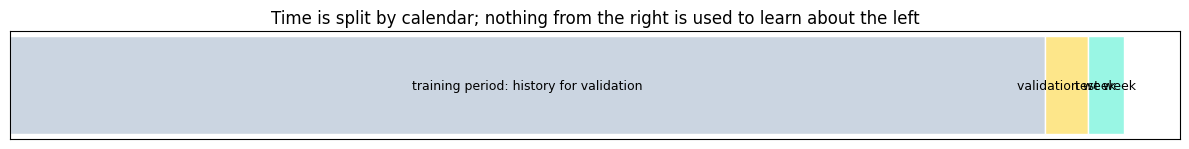

In [7]:
# the timeline, drawn from the actual dates
t = lambda ms: pd.to_datetime(ms, unit="ms")
start, v0, t0_, end = t(split.train.timestamp.min()), t(val.labels.timestamp.min()), t(test.labels.timestamp.min()), t(test.labels.timestamp.max())
fig, ax = plt.subplots(figsize=(12, 1.6))
for a, b, c, lab in [(start, v0, "#cbd5e1", "training period: history for validation"), (v0, t0_, "#fde68a", "validation week"), (t0_, end, "#99f6e4", "test week")]:
    ax.barh(0, (b - a).days, left=a.toordinal(), color=c, edgecolor="white"); ax.text(a.toordinal() + (b - a).days / 2, 0, lab, ha="center", va="center", fontsize=9)
ax.set_yticks([]); ax.set_xticks([]); ax.set_title("Time is split by calendar; nothing from the right is used to learn about the left"); plt.tight_layout(); plt.show()

**How to read this.** The history for the test starts at the left edge and stops at the test week; the model never sees the test week.
Only about **10% of eligible customers** buy something in a given week, and **recall is undefined for customers who buy nothing**. So we can only score customers who bought in the test week.
That is a real limitation (we measure "how well do we guess what active buyers pick up next", not "how good is the system for every visitor"), and it applies equally to every model, so comparisons between models stay fair.

## 3. The metrics, built from scratch

We recommend a list of 12 articles per customer; the customer's **truth** is the set of articles they actually bought in the test week.

- **recall@12**: of the articles the customer really bought, what fraction did our 12 contain? One customer: `hits / number_bought`. We average over customers.
- **NDCG@12**: like recall, but a hit near the top of the list counts more than a hit at position 12. Each hit at rank *r* (1 is best) is worth `1 / log2(r + 1)`, and the total is divided by the best possible total, so a perfect list scores 1.
- **coverage**: the share of the catalogue that appears in at least one customer's list. Low coverage means the system recommends the same few articles to everyone.

Here they are on a toy example, computed by hand and by the project's functions, so you can see they agree.

In [8]:
from src.metrics import recall_at_k, ndcg_at_k, coverage

recs  = np.array([[7, 3, 9, 1, 4, 8, 2, 5, 6, 0, 10, 11]])   # our 12 recommended article ids, best first
truth = [{3, 11, 99}]                                          # customer really bought articles 3, 11 and 99 (99 was never recommended)

hits = [r in truth[0] for r in recs[0]]
recall = sum(hits) / len(truth[0])
dcg = sum(h / np.log2(rank + 2) for rank, h in enumerate(hits))             # rank 0 -> log2(2), rank 1 -> log2(3), ...
ideal = sum(1 / np.log2(rank + 2) for rank in range(min(len(truth[0]), 12)))  # best case: all 3 purchases at the top
print(f"hand-computed: recall@12 = {recall:.4f}, NDCG@12 = {dcg / ideal:.4f}")
print(f"project code : recall@12 = {recall_at_k(recs, truth):.4f}, NDCG@12 = {ndcg_at_k(recs, truth):.4f}")

hand-computed: recall@12 = 0.6667, NDCG@12 = 0.4229
project code : recall@12 = 0.6667, NDCG@12 = 0.4229


**How to read this.** Two of the three purchases were in the list (articles 3 and 11), so recall is 2/3. The NDCG is lower than that because one hit is at position 2 and the other at position 12.
To feel the scale: our final model gets recall@12 of about **0.055**. That sounds tiny, but a catalogue of ~34,000 articles, one week of behaviour and 12 slots make this a hard problem; a random list would score about 0.0004 and "recommend the most popular items" about 0.007.

## 4. Baselines: how far do simple ideas go?

Before any machine learning, we measure simple rules. They are our yardstick: a fancy model is only interesting if it clearly beats them. (`src/baselines.py`)

| Baseline | Idea |
|---|---|
| **Popularity** | recommend what sold most over all history |
| **Recent popularity** | what sold most in the last 14 days (trending) |
| **Co-occurrence** | "people who bought what you bought also bought...": articles are similar if the same customers bought both (cosine similarity); score = similarity to what *you* bought |
| **Recency-weighted co-occurrence** | the same, but your recent purchases count more: each purchase is weighted `exp(-age / tau)` with `tau = 30` days |

In every case articles the customer already bought are never recommended.

We evaluate on a **sample of test customers** (`N_TEST`) to keep this quick.

evaluating on 5,000 test customers


[    40s] Popularity (all time)


[    41s] Recent popularity (14 days)


[    45s] Co-occurrence


[    48s] Recency-weighted co-occurrence


,recall@12,NDCG@12,coverage
model,,,
Popularity (all time),0.0077,0.0050,0.0005
Recent popularity (14 days),0.0271,0.0161,0.0005
Co-occurrence,0.0242,0.0143,0.2740
Recency-weighted co-occurrence,0.0316,0.0198,0.3926


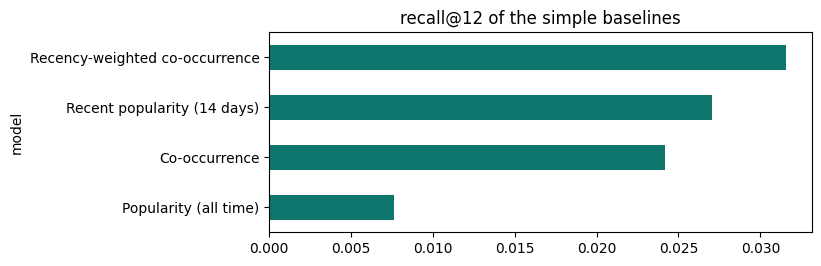

In [9]:
from src.baselines import Popularity, ItemCooccurrence, RecencyCooccurrence, RecentPopularity, recommend

users_all, truth_all = test.truth()
pick = np.random.default_rng(SEED).permutation(len(users_all))[: (N_TEST or len(users_all))]
users = users_all[pick]
truth = [truth_all[i] for i in pick]
print(f"evaluating on {len(users):,} test customers")

binary = test.binary()                       # customer x article 0/1 matrix of everything bought before the test week
models = {
    "Popularity (all time)":              Popularity().fit(binary),
    "Recent popularity (14 days)":        RecentPopularity().fit(binary, test.recent_counts(14)),
    "Co-occurrence":                      ItemCooccurrence().fit(binary),
    "Recency-weighted co-occurrence":     RecencyCooccurrence().fit(binary, test.decayed(30)),
}
rows = []
for name, m in models.items():
    recs = recommend(m, users, K)
    rows.append((name, recall_at_k(recs, truth), ndcg_at_k(recs, truth), coverage(recs, test.n_items)))
    tick(name)
base = pd.DataFrame(rows, columns=["model", "recall@12", "NDCG@12", "coverage"]).set_index("model")
display(base)
base["recall@12"].sort_values().plot.barh(color="#0f766e", figsize=(7, 2.6), title="recall@12 of the simple baselines"); plt.show()

**How to read this.** README values on all 40,188 customers: popularity 0.0072, co-occurrence 0.0210, recent popularity 0.0284, recency-weighted co-occurrence 0.0323. With a 5,000-customer sample your numbers will move by a few thousandths (the order of the models is the stable part).
The *coverage* column is not comparable with the README either: it counts how much of the catalogue appears across the customers you evaluated, so it grows with the sample size. Compare coverage only between rows of the same table.
Two lessons:

1. **Recency is the biggest single lever.** Weighting your history by how recent each purchase is lifts co-occurrence by about 50%.
2. **"What is trending now" alone beats plain co-occurrence.** Fashion demand follows the calendar. But look at the *coverage* column: recent popularity recommends almost the same articles to everyone, so it is not personal at all.

The next cell shows what the recency weights look like, so `tau` stops being abstract.

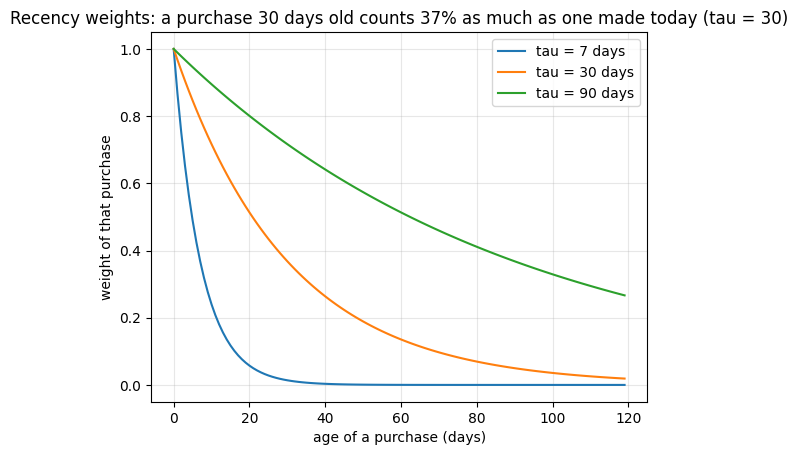

In [10]:
age = np.arange(0, 120)
for tau in (7, 30, 90):
    plt.plot(age, np.exp(-age / tau), label=f"tau = {tau} days")
plt.xlabel("age of a purchase (days)"); plt.ylabel("weight of that purchase"); plt.legend(); plt.grid(alpha=.3)
plt.title("Recency weights: a purchase 30 days old counts 37% as much as one made today (tau = 30)"); plt.show()

## 5. Article text embeddings (content similarity)

**What and why.** Co-occurrence only works for articles that have been bought. A brand-new article has no purchases, but it does have a **name, category, colour and description**. We turn that text into a vector so that similar articles end up close together:

1. Concatenate the article's text fields.
2. **TF-IDF**: weight words by how distinctive they are (rare words matter more).
3. **SVD** to 128 dimensions: compress, so articles can be compared cheaply.

(`src/content.py`.) The nearest neighbours of an article should *look like* it. Let's check that, since this is the only way to trust an embedding.

In [11]:
from src.content import build_item_embeddings, load_item_meta, ContentKNN

emb = build_item_embeddings(str(DATA / "articles.csv"), split.item_ids)     # (n_items, 128), rows are unit length
meta = load_item_meta(str(DATA / "articles.csv"), split.item_ids)           # category codes, used later as ranker features
tick(f"embeddings {emb.shape}")

def label(i):
    a = arts_by_id.loc[split.item_ids[i]]
    return f"{a.prod_name} ({a.colour_group_name} {a.product_type_name.lower()})"

query = int(np.argmax(np.bincount(test.hist.i.values, minlength=test.n_items)))   # the most-bought article
sims = emb @ emb[query]
neighbours = np.argsort(-sims)[:6]
print("query article:", label(query), "\n")
for j in neighbours[1:]:
    print(f"  similarity {sims[j]:.2f}  ->  {label(j)}")

[    52s] embeddings (33801, 128)
query article: Tilly (1) (Black t-shirt) 

  similarity 0.98  ->  Talia (1) (Black t-shirt)
  similarity 0.94  ->  Tilly (1) (Black t-shirt)
  similarity 0.94  ->  Tilly (1) (Black t-shirt)
  similarity 0.94  ->  Tilly (1) (Black t-shirt)
  similarity 0.94  ->  Tilly (Black t-shirt)


**How to read this.** The neighbours should be the same kind of garment (similar type, similar wording). That is all we ask of the embedding.

As a recommender, the **content model** builds a profile for each customer as the average embedding of what they bought (recent purchases weighted more) and recommends the closest articles.
It only looks at descriptions, never at what other customers did, so it is weak for existing customers (README: about 0.012) but it is the one that can score articles nobody has bought yet.

In [12]:
content_model = ContentKNN(emb).fit(test.decayed(7))
recs = recommend(content_model, users, K)
print(f"Content similarity: recall@12 = {recall_at_k(recs, truth):.4f}  (README, all customers: 0.0122)")

Content similarity: recall@12 = 0.0118  (README, all customers: 0.0122)


## 6. Candidate generation: build a pool, then rank it

**What and why.** Real systems work in two stages because scoring every article with a heavy model for every customer is too expensive:

- **Stage 1, retrieval:** cheap rules propose a few hundred *candidates* per customer.
- **Stage 2, ranking:** a learned model orders those candidates and keeps 12.

Our four generators from section 4/5 each propose their top articles (60, 20, 30 and 20) and the union is the candidate pool, about **112 candidates per customer**.
`CandidateBuilder` (in `src/ranker.py`) also records *which generator proposed each candidate* and computes the features the ranker will use.

**Why a two-stage design limits the system:** the ranker can only order what stage 1 supplies. If the article a customer will buy is not in the pool, nothing downstream can recover it. So we measure the pool itself:

- **candidate recall**: of what the customer really bought, how much is in the pool? (An upper bound on recall@12.)
- **hit rate**: the share of customers with *at least one* purchase in the pool.

Building the pool for many customers takes a few minutes: it scores every article with every generator.

In [13]:
from src.ranker import CandidateBuilder, GEN_N
from src.retrieval_analysis import pool_stats, contributions

n_true = test.labels.groupby("u").size()                    # how many articles each test customer really bought

rng = np.random.default_rng(SEED)
val_users_all = val.truth()[0]
val_users = rng.permutation(val_users_all)[: (N_TRAIN or len(val_users_all))]
test_users = users                                           # the same sample as in section 4

builder_val = CandidateBuilder(val, meta, emb)               # one builder per phase: it prepares similarity matrices once
train_df = builder_val.build(val_users);  tick(f"validation candidates: {len(train_df):,} rows")
builder_test = CandidateBuilder(test, meta, emb)
test_df = builder_test.build(test_users); tick(f"test candidates:       {len(test_df):,} rows")

per_customer, cand_recall, hit_rate = pool_stats(test_df, n_true)
print(f"\ncandidates per customer: {per_customer:.0f} | candidate recall: {cand_recall:.3f} | hit rate: {hit_rate:.3f}")
display(test_df.head(3).T.head(12))

[    85s] validation candidates: 1,681,307 rows


[    98s] test candidates:       561,438 rows

candidates per customer: 112 | candidate recall: 0.134 | hit rate: 0.266


,0,1,2
u,397912,397912,397912
i,748,837,1962
src_rcooc,False,False,False
src_cooc,False,False,False
src_rpop,True,True,False
src_content,False,False,True
rcooc_score,0.0555,0.0218,0.0089
rcooc_rel,0.2736,0.1076,0.0439
cooc_score,0.1755,0.0688,0.0623
rpop_score,576.0000,475.0000,0.0000


**How to read this.** (README values for the four-generator pool: about 112 candidates, candidate recall 0.13, hit rate 0.26.)

- Only about **a quarter of customers have even one of their next-week purchases in the pool**. Fashion buying in a single week is only partly predictable from history. This is the hard ceiling for everything after.
- The table shows a few candidate rows: `u` is the customer, `i` the article, `y` is **1 if the customer really bought it** (the label the ranker learns from), `*_score` columns are the generators' scores, and `src_*` say which generators proposed it.

Which generator contributes what? The next cell answers it, and it is a good test of whether you have understood the pool.

In [14]:
contributions(test_df, n_true)


## Generator contributions (test week, default pool, 5000 customers)
pool: 112 candidates per customer, candidate recall 0.1338, mean sources per candidate 1.16
| Generator | candidates per customer | recall of its own candidates | unique candidates per customer | candidate recall without it |
|---|---|---|---|---|
| rcooc | 60 | 0.0755 | 43.8 | 0.0972 |
| cooc | 20 | 0.0324 | 7.8 | 0.1289 |
| rpop | 30 | 0.0585 | 28.1 | 0.0851 |
| content | 20 | 0.0161 | 16.2 | 0.1294 |

Jaccard overlap of candidate sets (pooled over customers):
| | rcooc | cooc | rpop | content |
|---|---|---|---|---|
| rcooc | 1.00 | 0.18 | 0.02 | 0.05 |
| cooc | 0.18 | 1.00 | 0.01 | 0.03 |
| rpop | 0.02 | 0.01 | 1.00 | 0.00 |
| content | 0.05 | 0.03 | 0.00 | 1.00 |


**How to read this.** (README on all customers: recency co-occurrence 60 candidates, recent popularity 30, co-occurrence 20, content 20; removing recent popularity cuts candidate recall most.)

- **"unique candidates"** are articles *only* that generator proposed. The generators barely overlap (mean sources per candidate is close to 1), so they are **complementary**: each finds articles the others miss. That is the reason to combine them.
- **"candidate recall without it"** answers "what if we removed this generator?". Recent popularity is not personalised, yet removing it hurts the pool the most: what is trending this week matters in fashion.
- The Jaccard table says the same thing: overlap between generators is tiny.

## 7. Features: what the ranker gets to look at

For each (customer, candidate article) row the ranker sees a vector of numbers. Grouped by meaning:

| Group | Columns | Intuition |
|---|---|---|
| Generator scores | `rcooc_score`, `cooc_score`, `rpop_score`, `content_score` and relative versions (`*_rel`) | what each simple method thinks of this pair |
| Article popularity | `item_pop`, `item_pop7`, `item_pop28` | how much it sold overall, in the last 7 and 28 days |
| Article facts | `item_price`, `item_age` | price, and days since first purchase (new arrivals sell differently) |
| Customer facts | `user_n`, `user_n28`, `user_recency` | how active they are, and how long since they last bought |
| Fit | `price_ratio`, `aff_*` | article price vs the customer's usual price; how much of the customer's history is in this article's product type, colour, department |
| Article attributes | `cat_*` | the article's product type, colour, department... as categories |

The columns `u`, `i`, `y` and `src_*` are **not** features: they identify the row, hold the answer, or record provenance. Using `y` as a feature would be cheating; `FEATURES_EXCLUDE` guards against that.

In [15]:
from src.run_ranker import FEATURES_EXCLUDE

feats = [c for c in train_df.columns if c not in FEATURES_EXCLUDE]
groups = {"generator scores": [c for c in feats if c.endswith(("_score", "_rel"))],
          "article popularity": [c for c in feats if c.startswith("item_pop")],
          "article facts": ["item_price", "item_age"],
          "customer facts": ["user_n", "user_n28", "user_recency"],
          "fit": ["price_ratio"] + [c for c in feats if c.startswith("aff_")],
          "article attributes": [c for c in feats if c.startswith("cat_")]}
assert sorted(sum(groups.values(), [])) == sorted(feats), "every feature should be in exactly one group"
for g, cols in groups.items():
    print(f"{g:20s} {len(cols):2d} features: {', '.join(cols)}")
print(f"\nrows: {len(train_df):,} | positives (y = 1): {int(train_df.y.sum()):,} = {train_df.y.mean():.2%} of rows (heavily imbalanced, as always in recommendation)")

# one real row, translated to words
row = test_df[test_df.y == 1].iloc[0]
print("\nOne candidate the customer really bought next week:", label(int(row.i)))
display(row[feats].to_frame("value").head(14))

generator scores      6 features: rcooc_score, rcooc_rel, cooc_score, rpop_score, content_score, content_rel
article popularity    3 features: item_pop, item_pop7, item_pop28
article facts         2 features: item_price, item_age
customer facts        3 features: user_n, user_n28, user_recency
fit                   5 features: price_ratio, aff_product_type_no, aff_colour_group_code, aff_department_no, aff_index_group_no
article attributes    6 features: cat_product_type_no, cat_colour_group_code, cat_department_no, cat_index_group_no, cat_garment_group_no, cat_graphical_appearance_no

rows: 1,681,307 | positives (y = 1): 4,547 = 0.27% of rows (heavily imbalanced, as always in recommendation)

One candidate the customer really bought next week: Dusk Padded T-shirt (Dark Purple bra)


,value
rcooc_score,0.1644
rcooc_rel,0.8247
cooc_score,0.2132
rpop_score,136.0000
content_score,0.7860
content_rel,0.8823
item_pop,625.0000
item_pop7,50.0000
item_pop28,298.0000
item_price,0.0165


**How to read this.** Every feature belongs to exactly one group (the `assert` checks). Only about 1% of rows are positives: out of ~112 candidates, a customer buys at most a couple.
The single row at the end is a real (customer, article) pair that *was* bought. Its feature values are what the ranker learns to associate with a purchase.

**Important:** all of these are computed *only from history before the label week*. That is checked per phase. A feature that peeks at the label week (for instance "popularity during the test week") would inflate results and is exactly the kind of leak a reviewer will probe.

## 8. The ranker

**What and why.** We train a **LightGBM** model (gradient-boosted decision trees) on the *validation* phase: its candidates and features come from history before the validation week, and its labels are what customers bought *in* the validation week. It then ranks the test-phase candidates.
So the ranker has never seen the test week.

Details worth knowing (`fit_ranker` in `src/run_ranker.py`):
- **One ranking group per customer**: LightGBM learns to order the candidates *within* each customer.
- Objective **LambdaRank**, which optimises a ranking metric directly. (In the README experiments a plain binary objective tied it, so I do not claim LambdaRank is better here.)
- 20% of customers are held out for **early stopping**, so the trees stop being added when they stop helping.

In [16]:
from src.run_ranker import fit_ranker

t1 = time.time()
ranker = fit_ranker(train_df, feats, K, np.random.default_rng(SEED), seed=SEED)
print(f"trained in {time.time() - t1:.0f}s with {ranker.best_iteration_} trees (best iteration chosen by early stopping)")
test_df["score"] = ranker.predict(test_df[feats])

trained in 5s with 129 trees (best iteration chosen by early stopping)


**Evaluating fairly.** The ranker orders the *same candidates* as the simple methods. To judge it, we compare three ways to turn the same candidate table into a top-12 list:

1. the **best single generator** (recency-weighted co-occurrence score),
2. **rank fusion**: each generator ranks the candidates, and we add up `1 / (60 + rank)`. No learning, just "combine the opinions",
3. the **LightGBM ranker**.

If the ranker is only as good as fusion, then all the learning added nothing. We also compute **95% bootstrap confidence intervals** (resample the *customers* 1,000 times) so we know how much of a difference is just luck about which customers are in the sample.

In [17]:
from src.analyze import per_user_metrics, boot_ci, paired_boot_diff, fmt

rr = np.zeros(len(test_df))
for g in ["rcooc_score", "cooc_score", "rpop_score", "content_score"]:
    rr += 1.0 / (60 + test_df.groupby("u")[g].rank(ascending=False, method="first").values)

scored = {"best single generator": test_df["rcooc_score"].values, "rank fusion (no learning)": rr, "LightGBM ranker": test_df["score"].values}
per = {name: per_user_metrics(test_df, s, n_true) for name, s in scored.items()}
common = sorted(set.intersection(*[set(v.index) for v in per.values()]))
per = {k: v.loc[common] for k, v in per.items()}

rng_b = np.random.default_rng(1)
table = pd.DataFrame({name: {"recall@12": fmt(boot_ci(m["recall"].values, rng_b)), "NDCG@12": fmt(boot_ci(m["ndcg"].values, rng_b))} for name, m in per.items()}).T
display(table)

d1 = paired_boot_diff(per["LightGBM ranker"]["recall"].values, per["best single generator"]["recall"].values, rng_b)
d2 = paired_boot_diff(per["LightGBM ranker"]["recall"].values, per["rank fusion (no learning)"]["recall"].values, rng_b)
print(f"\nranker minus best generator: {fmt(d1)}")
print(f"ranker minus rank fusion:    {fmt(d2)}")

,recall@12,NDCG@12
best single generator,"0.0316 [0.0275, 0.0357]","0.0198 [0.0173, 0.0225]"
rank fusion (no learning),"0.0391 [0.0349, 0.0436]","0.0249 [0.0219, 0.0279]"
LightGBM ranker,"0.0504 [0.0457, 0.0551]","0.0321 [0.0290, 0.0352]"



ranker minus best generator: 0.0189 [0.0147, 0.0234]
ranker minus rank fusion:    0.0113 [0.0070, 0.0156]


**How to read this.** Each cell is `mean [95% interval]`. (README, all customers, 5 seeds: ranker 0.0551, best generator 0.0323, fusion 0.0398.)

- The "minus" lines are **paired differences**: same customers, ranker versus the alternative. If the interval does **not include zero**, the difference is not just sampling luck. That is the right way to compare two models on the same customers; do not compare two separate intervals by eye.
- Notice what the paired difference against *fusion* means: simply combining signals gets part of the gain; learning gets more. Be ready to say both.
- With a smaller sample than the README, your intervals are wider (about +/-0.005 for 5,000 customers, against +/-0.0018 for all 40,188), and the ranker is trained on fewer customers, so its absolute recall is a little lower than the README's 0.0551.

Which features did the model rely on?

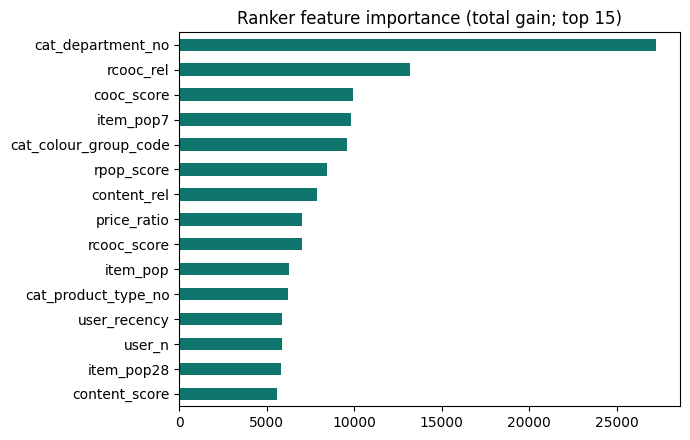

In [18]:
imp = pd.Series(ranker.booster_.feature_importance("gain"), index=feats).sort_values()
imp.tail(15).plot.barh(figsize=(7, 4.5), color="#0f766e", title="Ranker feature importance (total gain; top 15)")
plt.tight_layout(); plt.show()

**How to read this.** "Gain" is how much each feature improved the model's splits in total. Typically article attributes (department, colour), the recency co-occurrence score and article popularity over the last 7 and 28 days are near the top; the exact order changes a little from run to run.
Treat this as a **hint, not proof**: importance of correlated features is shared arbitrarily, and the proper test is the ablation in the README (retrain without a feature group), where removing the article statistics hurt the most.

## 9. Looking at real recommendations

Numbers are one thing; whether the output *makes sense* is another. For a few test customers: what they bought recently, what we recommend, and what they actually bought next week.
Every article gets a text label. Pictures appear for the articles in `demo/images`, and for **any** article if you set `IMAGES_ZIP` (the competition's `images.zip`) in the setup cell; otherwise you see a grey box.

pictures from: images.zip


Therese tee (White t-shirt),Therese tee (Black t-shirt),Pink HW barrel (Light Grey trouser,LW (K) Rose conc rib trs (Light Or,Woody hoodie (Black hoodie),LW (K) Rose cons rib polo (Light O
Jenka sweatshirt (Beige sweater),Pink HW barrel (Light Beige trouse,Jasba jersey shacket (Light Beige,Morris (Off White sweater),LW (J) consc PRICE jogger (Light B,LW (K) Rose conc rib trs (Black tr
Jackie cable vest (Off White sweat,LW (J) VERONIKA Consc Trs (Beige p,LW (J) Conc PRICE SWEATSHIRT (Ligh,Nika vest (Off White sweater),Lava (Off White sweater),Sandy (Beige sweater)
Highwaist 30 den 1p Tights (Black,S. Skinny HW Ankle Star Consc (Blu,Liliana (Black sweater),Jackie brief 2pk HR LS (Black unde,Miley LL Satin PJ (W) (Black pyja,LW (J) consc PRICE jogger (Light B

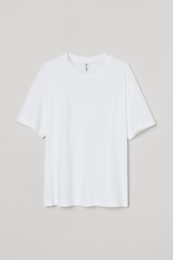
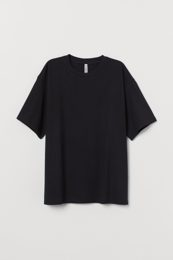
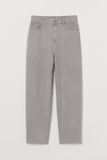
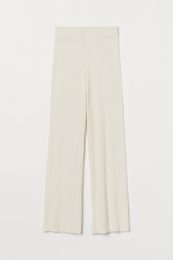
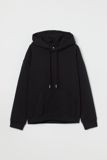
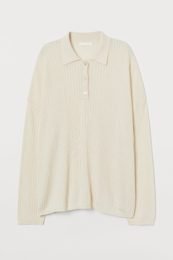
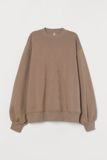
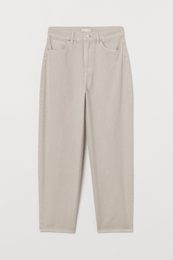
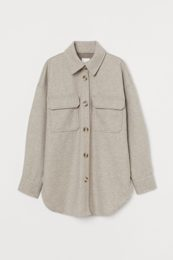
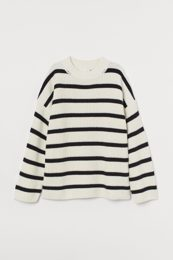
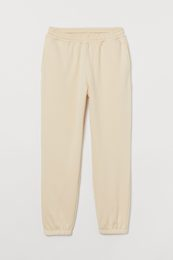
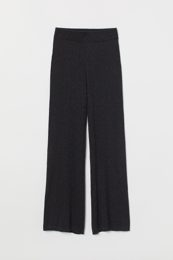
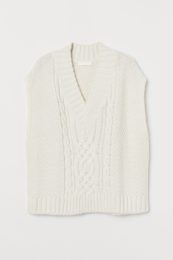
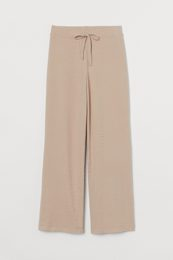
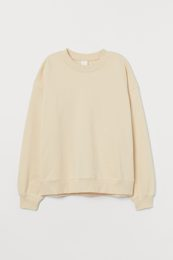
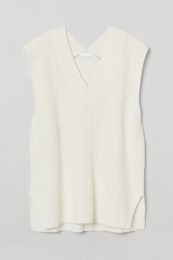
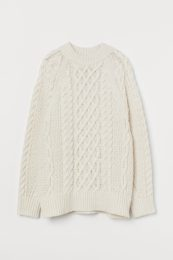
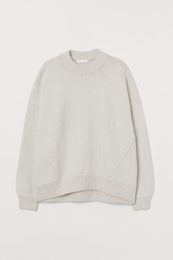
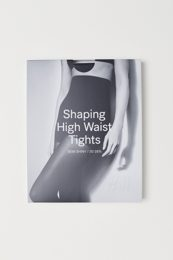
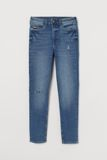
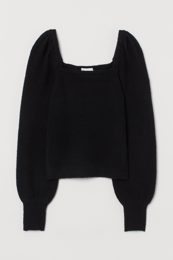
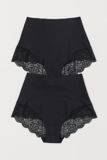
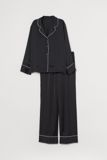
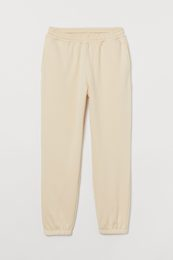


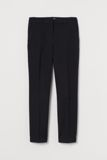
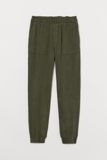
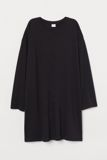
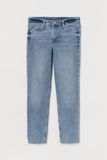
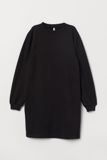
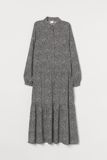
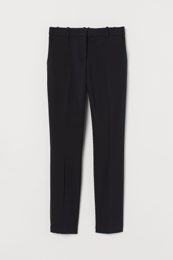
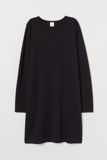
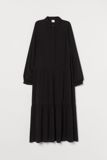
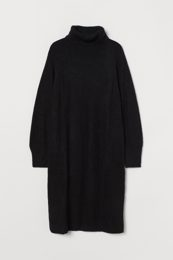
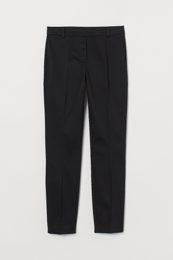
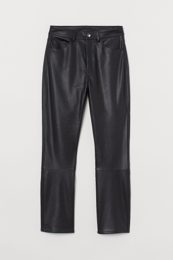
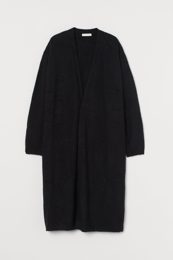
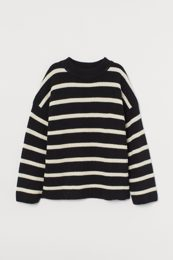
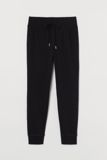
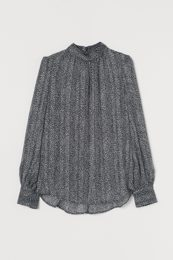
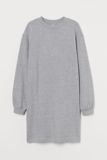
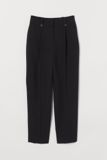
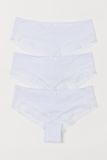
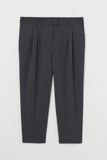

In [19]:
import base64, zipfile
from io import BytesIO
from PIL import Image as PILImage

IMG = REPO / "demo" / "images"
zf = zipfile.ZipFile(IMAGES_ZIP) if IMAGES_ZIP and Path(IMAGES_ZIP).exists() else None
print("pictures from:", "images.zip" if zf else "demo/images only (set IMAGES_ZIP for every article)")

def aid10(item_code): return str(int(split.item_ids[item_code])).zfill(10)

def jpeg_b64(aid):
    p = IMG / f"{aid}.jpg"
    if p.exists():
        return base64.b64encode(p.read_bytes()).decode()
    if zf is not None:
        try:
            with zf.open(f"{aid[:3]}/{aid}.jpg") as fh, PILImage.open(BytesIO(fh.read())) as im:
                im = im.convert("RGB"); im.thumbnail((120, 160))
                buf = BytesIO(); im.save(buf, "JPEG", quality=80); return base64.b64encode(buf.getvalue()).decode()
        except KeyError:
            return None
    return None

def thumbs(codes, caption):
    cells = []
    for c in codes:
        b64 = jpeg_b64(aid10(c))
        img = f'<img src="data:image/jpeg;base64,{b64}" width="90"><br>' if b64 else '<div style="width:90px;height:110px;background:#eee"></div>'
        cells.append(f'<td style="text-align:center;font-size:11px;padding:3px">{img}{label(c)[:34]}</td>')
    return f"<p><b>{caption}</b></p><table><tr>{''.join(cells)}</tr></table>"

def show_customer(u):
    hist = test.hist[test.hist.u == u].sort_values("timestamp").tail(6).i.tolist()
    top = test_df[test_df.u == u].sort_values("score", ascending=False).head(K)
    bought = test.labels[test.labels.u == u].i.tolist()[:6]
    hits = int(top.y.sum())
    html = f"<h4>Customer {u}: {hits} of {K} recommendations were bought the following week</h4>"
    html += thumbs(hist, "Recently bought")
    html += thumbs(top.i.astype(int).tolist()[:6], "Recommended, ranks 1 to 6") + thumbs(top.i.astype(int).tolist()[6:], "Recommended, ranks 7 to 12")
    html += thumbs(bought, "Actually bought that week (up to 6)")
    display(HTML(html))

with_hit = test_df.groupby("u").y.sum()
for u in list(with_hit[with_hit > 0].index[:1]) + list(with_hit[with_hit == 0].index[:1]):
    show_customer(u)

**How to read this.** The first customer is one where a recommendation was right; the second is one with no hit, which is the *typical* outcome.
Look for whether the recommendations are plausible for that customer's history, not just whether they hit. A system with 5% recall@12 will mostly miss, and that is a feature of the problem, not a bug.

## 10. Does a bigger candidate pool help?

An obvious question: if only a quarter of customers have a purchase in the pool, why not make the pool bigger?
We scale all four generators' quotas together by 0.5, 1 and 2, retrain the ranker each time, and measure.
(README, full run, extra scale 3: candidate recall 0.09, 0.13, 0.19, 0.23 for 57, 112, 221 and 328 candidates; ranker recall@12 0.0528, 0.0552, 0.0565, 0.0563.)

[   145s] scale 0.5


[   188s] scale 1


[   235s] scale 2


,candidates per customer,candidate recall,hit rate,ranker recall@12,ranker NDCG@12
pool,,,,,
x0.5,56.7766,0.0928,0.1860,0.0502,0.0312
x1,112.2876,0.1338,0.2658,0.0504,0.0321
x2,221.2530,0.1900,0.3580,0.0519,0.0314


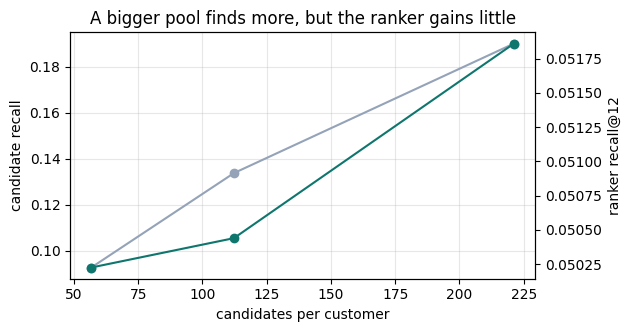

In [20]:
rows = []
for scale in (0.5, 1.0, 2.0):
    quotas = {k: max(1, int(round(v * scale))) for k, v in GEN_N.items()}
    builder_val.gen_n = builder_test.gen_n = quotas
    tr, te = builder_val.build(val_users), builder_test.build(test_users)
    m = fit_ranker(tr, feats, K, np.random.default_rng(SEED), seed=SEED)
    pu = per_user_metrics(te, m.predict(te[feats]), n_true)
    pc, cr, hr = pool_stats(te, n_true)
    rows.append((f"x{scale:g}", pc, cr, hr, pu.recall.mean(), pu.ndcg.mean()))
    tick(f"scale {scale:g}")
budget = pd.DataFrame(rows, columns=["pool", "candidates per customer", "candidate recall", "hit rate", "ranker recall@12", "ranker NDCG@12"]).set_index("pool")
display(budget)
builder_val.gen_n = builder_test.gen_n = {k: v for k, v in GEN_N.items()}      # restore the default pool

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(budget["candidates per customer"], budget["candidate recall"], "o-", label="candidate recall (what the pool contains)", color="#94a3b8")
ax2 = ax.twinx(); ax2.plot(budget["candidates per customer"], budget["ranker recall@12"], "o-", label="ranker recall@12 (what we deliver)", color="#0f766e")
ax.set_xlabel("candidates per customer"); ax.set_ylabel("candidate recall"); ax2.set_ylabel("ranker recall@12"); ax.grid(alpha=.3)
plt.title("A bigger pool finds more, but the ranker gains little"); plt.show()

**How to read this.** With a sample, differences in the ranker's recall between pool sizes are small compared with the noise (compare them with the seed spread in section 13), so read the *shape*, and use the README's full-run numbers for the actual values. Candidate recall (grey) rises steadily with the pool. The ranker's recall@12 (green) rises much more slowly and flattens: the extra articles it finds are *harder to rank into the top 12*. Beyond a modest pool the bottleneck is the ranker (and the genuine unpredictability of next-week buying), not retrieval volume.
Also note how few customers have a hit even in the biggest pool. This is the honest answer to "why is recall so low?".

## 11. The two-tower neural model (read; optional run)

**The idea.** Two small neural networks (towers) map things into the same 64-dimensional space:
- the **user tower** reads the customer's last 20 purchases (their average and the most recent one) and outputs a customer vector,
- the **item tower** maps an article (an id embedding plus the text embedding from section 5) to an article vector.

A customer and an article match when their vectors point the same way (dot product). Training uses **sampled softmax**: for each real purchase, the other purchases in the same batch act as negatives, with a correction (`log-Q`) so that popular articles are not unfairly penalised.
During training the id embedding is randomly switched off for 30% of examples so the model also learns to rely on the text alone. That is what lets it score *brand-new* articles.

Because this needs PyTorch, it cannot run inside this notebook (see "Before you run anything"). The cell below only **displays the source**. Read it as you would read a model definition in an interview.

In [21]:
src = (REPO / "src" / "twotower.py").read_text()
start, end = src.index("class TwoTower"), src.index("def pick_device")
print(src[start:end])

class TwoTower(nn.Module):
    def __init__(self, n_items: int, content: np.ndarray, dim: int = 64):
        super().__init__()
        self.n_items = n_items
        self.register_buffer("content", torch.from_numpy(content))
        self.id_emb = nn.Embedding(n_items + 1, dim, padding_idx=n_items)
        nn.init.normal_(self.id_emb.weight, std=0.1)
        self.content_proj = nn.Linear(content.shape[1], dim)
        self.item_out = nn.Sequential(nn.LayerNorm(dim), nn.Linear(dim, dim))
        self.user_mlp = nn.Sequential(nn.Linear(2 * dim, 2 * dim), nn.ReLU(), nn.Linear(2 * dim, dim))
        self.log_scale = nn.Parameter(torch.tensor(float(np.log(14.0))))

    def item_vec(self, idx: torch.Tensor, id_gate: torch.Tensor | None = None) -> torch.Tensor:
        """id_gate: float tensor broadcastable to idx (1 = use id embedding, 0 = content only)."""
        x = self.content_proj(self.content[idx.clamp(max=self.n_items - 1)])
        ids = self.id_emb(idx)
        x = x + (ids if id_g

**Running it yourself (optional, about 5 minutes, runs as a separate process).** Set `RUN_TWOTOWER = True` and run the cell. It trains the model and prints its standalone recall on the validation and test weeks.
It writes caches under `data/hm/cache_train_s0/`, which you can delete afterwards.

In [22]:
RUN_TWOTOWER = False
if RUN_TWOTOWER:
    out = subprocess.run([sys.executable, "-u", "-m", "src.run_twotower", "data/hm"], cwd=REPO, capture_output=True, text=True)
    print(out.stdout[-1500:], out.stderr[-500:])
else:
    print("skipped (set RUN_TWOTOWER = True to run it)")

skipped (set RUN_TWOTOWER = True to run it)


**What the README results say (full run):**

| | recall@12 |
|---|---|
| Two-tower on its own | 0.0276, about the same as "recent popularity" (0.0284) |
| Ranker without it | 0.0552 +/- 0.0005 (3 seeds) |
| Ranker with it as a candidate source and a feature | 0.0558 +/- 0.0004 |

The two-tower generator raises candidate recall (0.130 to 0.153) but the final ranker's gain is about +0.0006 and **statistically indistinguishable from zero**.
An early single run suggested +0.0035; that came from one unlucky baseline run (see section 13), and I withdrew it. Do not claim the two-tower model improves the ranker.

## 12. Cold start: recommending articles nobody has bought (read; optional run)

**The problem.** New articles have no purchase history, so popularity and co-occurrence cannot score them. **The simulation** (`src/cold_start.py`):

1. take the articles bought in the test week and pick 10% at random (1,346 of 13,460),
2. delete every purchase of those articles from the history and retrain the two-tower model without them: to the model they are brand new,
3. for customers who bought one of them, rank **only those hidden articles** and see whether the customer's actual purchase is near the top.

Random ranking is the floor: any model that cannot score unseen articles falls back to random.

(Running it needs PyTorch, so as in section 11 it runs as a separate process and takes about 8 minutes.)

In [23]:
RUN_COLD_START = False
if RUN_COLD_START:
    out = subprocess.run([sys.executable, "-u", "-m", "src.cold_start", "data/hm"], cwd=REPO, capture_output=True, text=True)
    print(out.stdout[-1500:], out.stderr[-500:])
else:
    print("skipped (set RUN_COLD_START = True to run it)")

pd.DataFrame({"model": ["Random", "Popularity", "Item co-occurrence", "Content similarity", "Two-tower (id embedding off for new articles)"],
              "recall@12 (README, single run)": [0.0073, 0.0094, 0.0090, 0.0532, 0.0673]}).set_index("model")

skipped (set RUN_COLD_START = True to run it)


,"recall@12 (README, single run)"
model,
Random,0.0073
Popularity,0.0094
Item co-occurrence,0.0090
Content similarity,0.0532
Two-tower (id embedding off for new articles),0.0673


**How to read this.** Models that depend on purchase history cannot tell new articles apart and score about the same as random. The text-based models do far better (about 7x and 9x random).
Caveats you should state: this is **one run with one random choice of hidden articles**, evaluated only on customers who bought a hidden article, and it simulates *unseen article ids*, not a real product launch (real new products also differ in price, season and exposure).

## 13. How reliable are the numbers? (training seeds)

Everything above came from one trained ranker. A different random choice of early-stopping customers (and LightGBM's internal sampling) gives a slightly different model. How much?
Below we retrain with three different seeds on the same candidates and test customers.

In [24]:
res = []
for s in range(3):
    m = fit_ranker(train_df, feats, K, np.random.default_rng(s), seed=s)
    pu = per_user_metrics(test_df, m.predict(test_df[feats]), n_true)
    res.append((s, m.best_iteration_, pu.recall.mean(), pu.ndcg.mean()))
seeds = pd.DataFrame(res, columns=["seed", "trees (early stopping)", "recall@12", "NDCG@12"]).set_index("seed")
display(seeds)
print(f"recall@12 over seeds: mean {seeds['recall@12'].mean():.4f}, standard deviation {seeds['recall@12'].std():.4f}, range {seeds['recall@12'].min():.4f} to {seeds['recall@12'].max():.4f}")

,trees (early stopping),recall@12,NDCG@12
seed,,,
0,129,0.0504,0.0321
1,40,0.0520,0.0335
2,55,0.0511,0.0313


recall@12 over seeds: mean 0.0512, standard deviation 0.0008, range 0.0504 to 0.0520


**How to read this.** Look at the "trees" column first: early stopping picks very different numbers of trees for different seeds (a few dozen to over a hundred), because it reacts to noise in a small held-out set. On this sample that did not hurt much, but it can.
The standard deviation across seeds is the *training noise*. It is separate from the bootstrap interval, which measures the noise from *which customers happen to be in the test set*. A fair comparison needs both in mind.

**The lesson from this project.** An early single run of the ranker scored 0.0532 because early stopping halted after only 41 trees (typical runs use about 120); five seeds gave 0.0551 +/- 0.0004, and 0.0532 was below every one of them.
That unlucky run was my baseline for a comparison that made the two-tower model look useful, and the claim collapsed once I used seeds. **Never compare two single runs.** Compare seed averages, and use a paired interval for the difference.

## 14. Summary: what is safe to claim

**Results from the full run (README; main test week, recall@12, 40,188 customers):**

| Model | recall@12 |
|---|---|
| Popularity | 0.0072 |
| Co-occurrence | 0.0210 |
| Recent popularity (14 days) | 0.0284 |
| Two-tower alone | 0.0276 |
| Recency-weighted co-occurrence (best single generator) | 0.0323 |
| Rank fusion (no learning) | 0.0398 |
| **LightGBM ranker, 4 generators (mean of 5 seeds)** | **0.0551** +/- 0.0004 |

**Safe to say**
- The ranker is about **71% better in relative terms** than the best single generator (0.055 vs 0.032), and ahead of it in each of four consecutive test weeks (57% to 76%).
- It also beats rank fusion and a linear model on identical candidates; the gain over fusion is statistically clear.
- Evaluation is strictly time-based, eligibility is computed on training data only, and a chronology audit checks every fold.
- Seeds were repeated and bootstrap intervals reported. The two-tower model did **not** reliably help the ranker, but it helps on unseen articles in a simulation.
- Candidate retrieval caps the system: about a quarter of customers have a relevant article in the pool, and a bigger pool stops helping.

**Do not say**
- "71 percentage points" (it is relative: recall went from about 0.032 to 0.055).
- "The two-tower model improves the ranker", "LambdaRank beats a binary objective", "I solved cold start".
- Anything about serving, A/B tests, a feature store, SASRec, matrix factorisation or FAISS as *done* work. None of that is built.
- Anything comparing to the Kaggle leaderboard (different metric, repeat purchases excluded, only buyers scored).

**Where things live**

| What | File |
|---|---|
| loading and k-core, time split | `src/hm.py`, `src/data.py`, `src/phases.py` |
| baselines and metrics | `src/baselines.py`, `src/metrics.py`, `src/content.py` |
| candidates and features | `src/ranker.py` |
| ranker training | `src/run_ranker.py` |
| confidence intervals, fusion, ablations | `src/analyze.py` |
| retrieval analysis | `src/retrieval_analysis.py` |
| two-tower and cold start | `src/twotower.py`, `src/cold_start.py` |
| the whole pipeline in one command | `scripts/run_pipeline.sh` |
| the live demo | `demo/app.py` |

**Exercises that build real understanding**
1. Change `tau` in `RecencyCooccurrence` from 30 to 7 and to 90 and re-run section 4. Which is best and why?
2. Remove one feature group in section 8 (drop the columns from `feats`) and retrain. Does recall move by more than the seed noise from section 13?
3. In section 6, change the quotas in `GEN_N` so recent popularity proposes 10 instead of 30 candidates. What happens to candidate recall and to the final recall?
4. Set `N_TEST = None` and `N_TRAIN = None` (slow) and compare with the README numbers.